# Customer Churn Prediction
## Notebook 1: Data Understanding and Exploratory Data Analysis (EDA)

### Objective
Understand customer characteristics, inspect data quality, and identify patterns associated with customer churn.

### Dataset
IBM Telco Customer Churn dataset.

### Tools
Python, Pandas, Matplotlib, and Seaborn.

## 1. Data Loading and Cleaning

Load the raw dataset, inspect its structure, and prepare the data for analysis.

The `TotalCharges` column was initially stored as an object rather than a numeric data type. It was converted to numeric, and 11 records with missing `TotalCharges` values were removed. These records had a tenure of zero months.

The cleaned dataset contains 7,032 rows and 21 columns.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project directories
PROJECT_DIR = Path("..")

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

# Load dataset
file_path = RAW_DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(file_path)

print("Dataset loaded:", file_path)
print("Shape:", df.shape)

display(df.head())

Dataset loaded: ..\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [16]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).copy()

print("Cleaned dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Cleaned dataset shape: (7032, 21)
Missing values: 0


In [17]:
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

processed_path = PROCESSED_DATA_DIR / "customer_churn_cleaned.csv"

df.to_csv(processed_path, index=False)

print("Cleaned dataset saved to:", processed_path)

Cleaned dataset saved to: ..\data\processed\customer_churn_cleaned.csv


## 2. Customer Churn Distribution

Examine the distribution of customers who churned and those who remained.

The initial dataset contained 1,869 churned customers out of 7,043 records. After removing 11 records with missing `TotalCharges`, 1,869 churned customers remain among 7,032 records.

This indicates that the target variable is imbalanced, with more customers staying than leaving.

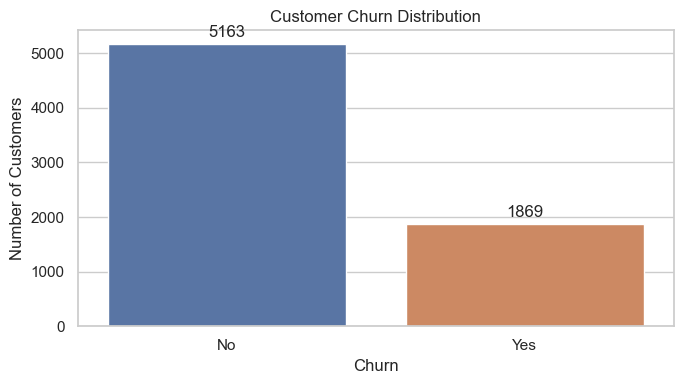

In [18]:
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    legend=False
)

# Add labels to both bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 3. Churn Analysis by Contract Type

Compare the churn rate across month-to-month, one-year, and two-year contracts.

### Key Findings
- Month-to-month contracts have a churn rate of 42.71%.
- One-year contracts have a churn rate of 11.28%.
- Two-year contracts have a churn rate of 2.85%.

### Business Insight
Customers with month-to-month contracts show substantially higher churn than customers with longer-term contracts.

### Recommendation
Evaluate targeted retention offers for month-to-month customers and investigate whether longer-term contract options improve customer retention.

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


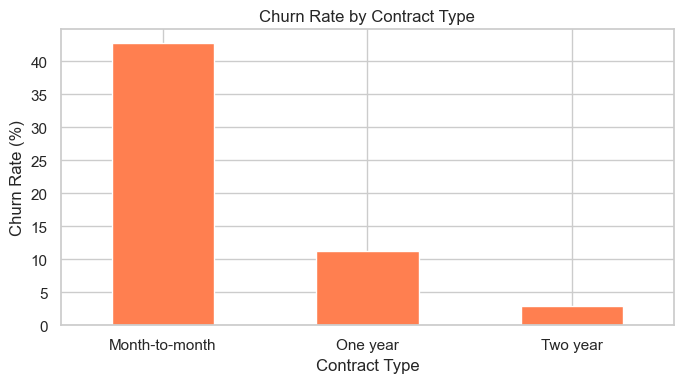

In [19]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

contract_churn["Yes"].plot(
    kind="bar",
    figsize=(7, 4),
    color="coral"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Churn Analysis by Customer Tenure

Customer tenure represents the number of months a customer has remained with the service. We examine churn rates across tenure groups to identify whether customer retention differs over time.

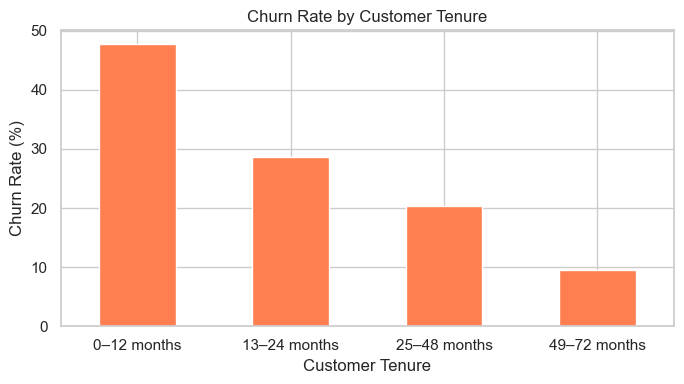

In [20]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months",
            "25–48 months", "49–72 months"]
)

tenure_churn = (
    pd.crosstab(
        df["TenureGroup"],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100
)

tenure_churn.plot(
    kind="bar",
    figsize=(7, 4),
    color="coral"
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Conclusion

The exploratory data analysis identified several patterns associated with customer churn.

- **Overall churn:** After data cleaning, the dataset contains 7,032 customers, of whom 1,869 (26.56%) churned.
- **Contract type:** Month-to-month customers have the highest churn rate at 42.71%, compared with 11.28% for one-year contracts and 2.85% for two-year contracts.
- **Customer tenure:** The churn rate is highest among customers with 0–12 months of tenure and decreases across the longer-tenure groups, reaching its lowest level among customers with 49–72 months of tenure.

### Business Recommendations

- Investigate the reasons for high churn among customers on month-to-month contracts.
- Prioritize early-tenure customers for onboarding support and targeted retention initiatives.
- Evaluate retention offers and longer-term contract options using controlled experiments.

These findings are exploratory associations and do not establish causation. The next stage will use classification models to evaluate how effectively customer characteristics predict churn.